# 05 · Conclusões: onde estará a demanda e o veredito

Os notebooks anteriores responderam **se** a demanda tech vai crescer. Este responde **onde** ela vai crescer —
usando as projeções oficiais do BLS por ocupação — e consolida o veredito com todas as evidências.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from techdemand import data_sources as ds, style

style.apply()
%matplotlib inline

bls = ds.load_bls_projections()
total = bls.set_index("soc_code").loc["00-0000"]
occ = bls[bls.level == "detailed"].copy()
traducao = {
    "Computer systems analysts": "Analistas de sistemas",
    "Information security analysts": "Analistas de segurança da informação",
    "Computer and information research scientists": "Cientistas de pesquisa em computação",
    "Computer network support specialists": "Suporte de redes",
    "Computer user support specialists": "Suporte ao usuário",
    "Computer network architects": "Arquitetos de redes",
    "Database administrators": "Administradores de banco de dados",
    "Database architects": "Arquitetos de banco de dados",
    "Network and computer systems administrators": "Administradores de sistemas e redes",
    "Computer programmers": "Programadores",
    "Software developers": "Desenvolvedores de software",
    "Software quality assurance analysts and testers": "QA e testes de software",
    "Web developers": "Desenvolvedores web",
    "Web and digital interface designers": "Designers de interface digital",
    "Computer occupations, all other": "Outras ocupações de computação",
    "Actuaries": "Atuários",
    "Mathematicians": "Matemáticos",
    "Operations research analysts": "Pesquisa operacional",
    "Statisticians": "Estatísticos",
    "Data scientists": "Cientistas de dados",
    "Mathematical science occupations, all other": "Outras de ciências matemáticas",
}
occ["ocupação"] = occ["title"].map(traducao)
assert occ["ocupação"].notna().all()
occ = occ[occ.employment_2025 >= 10]  # remove ocupações minúsculas (< 10 mil), cuja variação é ruído de arredondamento

## 1. Crescimento projetado por ocupação (BLS 2025–2035)

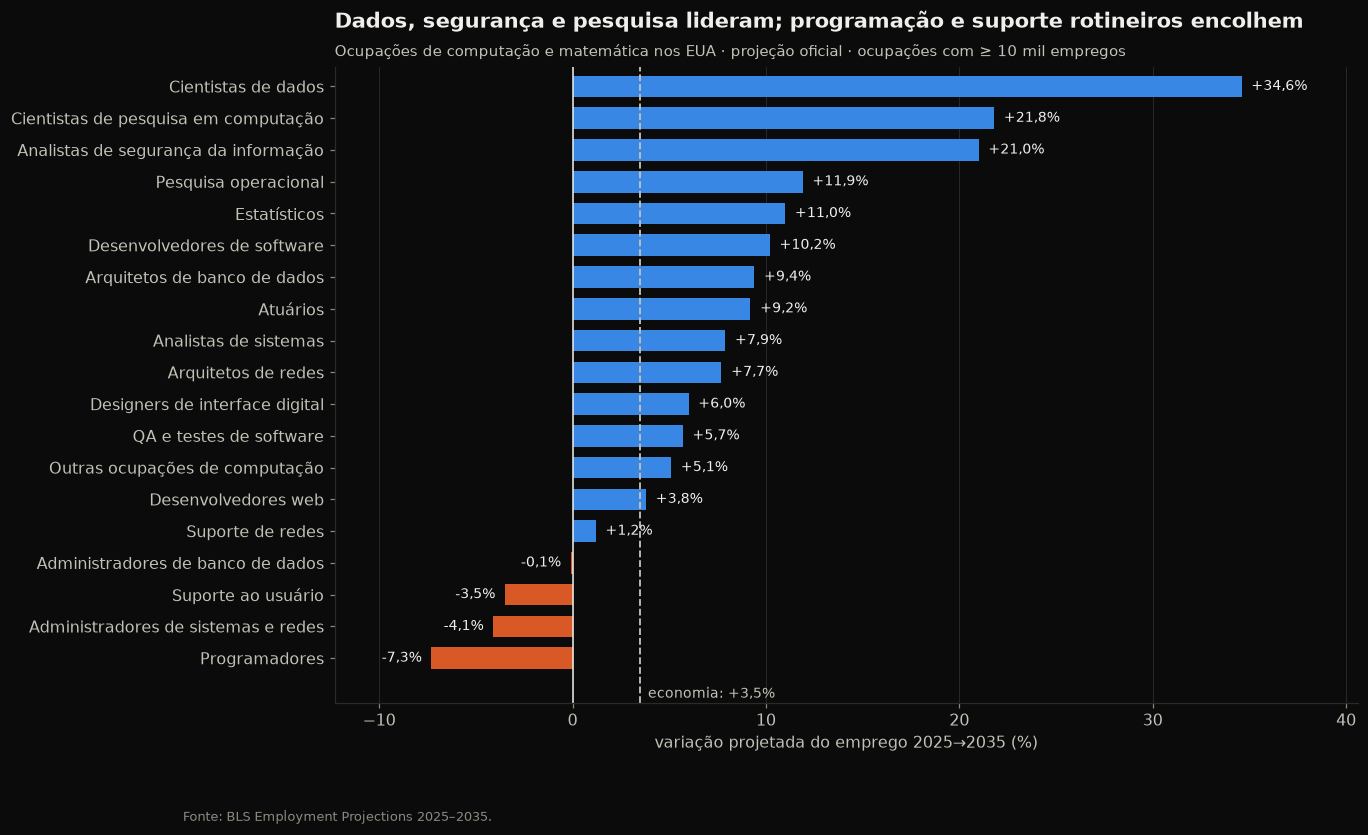

14 de 19 ocupações crescem acima da média da economia (+3.5%).


In [2]:
d = occ.sort_values("change_pct")
fig, ax = plt.subplots(figsize=(12, 7.5))
cores = [style.DIVERGING[0] if v < 0 else style.DIVERGING[2] for v in d.change_pct]
ax.barh(d["ocupação"], d["change_pct"], color=cores, height=0.68)
ax.axvline(0, color=style.TEXT_PRIMARY, lw=1)
ax.axvline(total.change_pct, color=style.TEXT_SECONDARY, lw=1.2, ls="--")
ax.text(total.change_pct + 0.4, -0.9, f"economia: +{style.fmt_num(total.change_pct, 1)}%", fontsize=9,
        color=style.TEXT_SECONDARY, va="top")
for i, (v, e) in enumerate(zip(d.change_pct, d.employment_2025)):
    ax.text(v + (0.5 if v >= 0 else -0.5), i, ("+" if v > 0 else "") + style.fmt_num(v, 1) + "%",
            va="center", ha="left" if v >= 0 else "right", fontsize=9, color=style.TEXT_PRIMARY)
ax.set_xlim(d.change_pct.min() - 5, d.change_pct.max() + 6)
ax.set_ylim(-1.4, len(d) - 0.4)
ax.grid(axis="y", visible=False)
ax.set_xlabel("variação projetada do emprego 2025→2035 (%)")
ax.set_title("Dados, segurança e pesquisa lideram; programação e suporte rotineiros encolhem")
style.subtitle(ax, "Ocupações de computação e matemática nos EUA · projeção oficial · ocupações com ≥ 10 mil empregos")
style.source(fig, "BLS Employment Projections 2025–2035.")
style.save(fig, "05_01_ocupacoes_crescimento")
plt.show()

acima = (occ.change_pct > total.change_pct).sum()
print(f"{acima} de {len(occ)} ocupações crescem acima da média da economia (+{total.change_pct}%).")

## 2. Crescimento × salário × vagas

Cada bolha é uma ocupação: eixo x = crescimento projetado, eixo y = salário mediano, tamanho = vagas abertas por ano
(inclui reposição por aposentadoria e troca de carreira — por isso mesmo ocupações estáveis abrem muitas vagas).

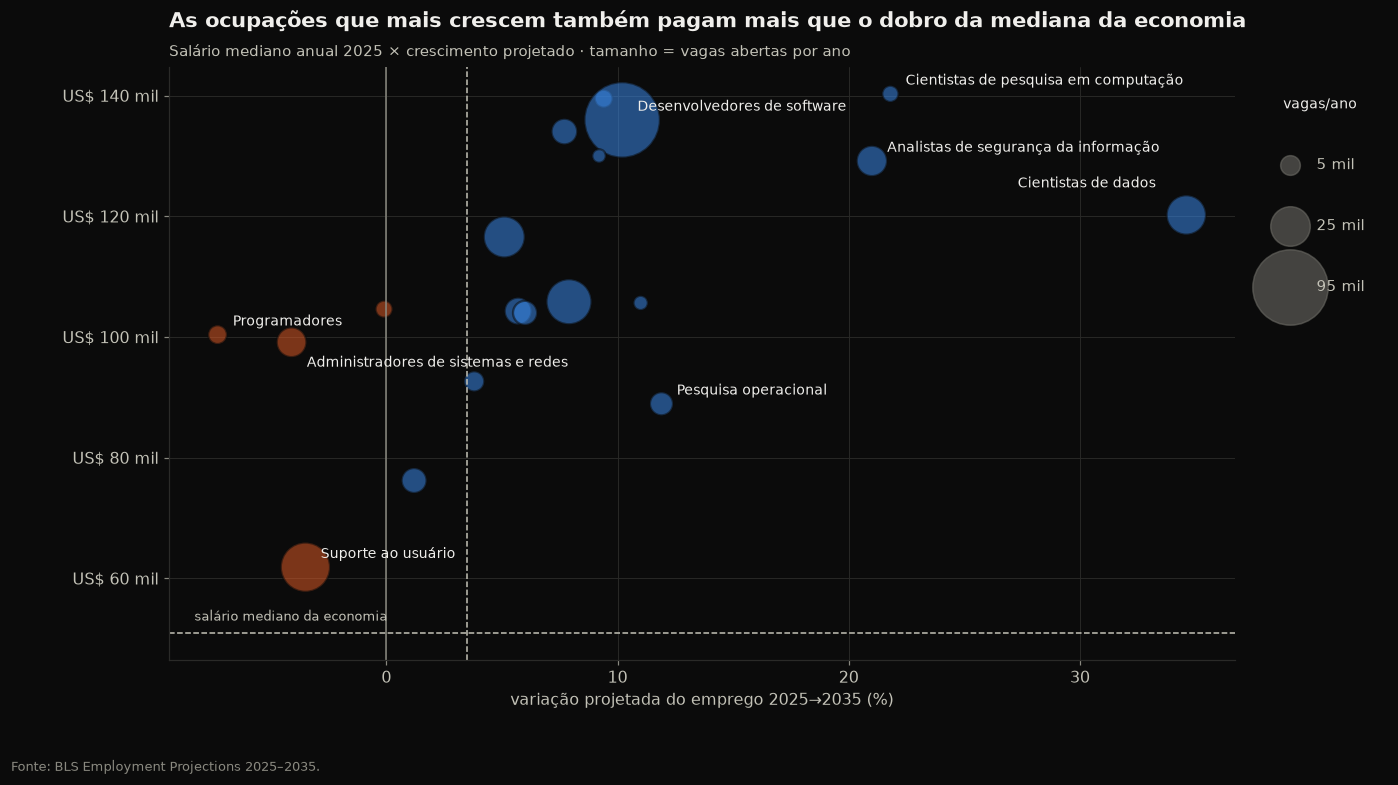

,Computação e matemática,Todas as ocupações
crescimento 2025–35 (%),7.3,3.5
vagas por ano (mil),316.1,17461.8
salário mediano (US$),109280.0,50980.0


In [3]:
fig, ax = plt.subplots(figsize=(12.5, 7))
x, y = occ.change_pct, occ.median_wage_2025 / 1000
tamanho = occ.annual_openings / occ.annual_openings.max() * 2400 + 40
cores = [style.DIVERGING[0] if v < 0 else style.DIVERGING[2] for v in x]
ax.scatter(x, y, s=tamanho, color=cores, alpha=0.55, edgecolor=style.SURFACE, lw=1.5)
ax.axvline(0, color=style.TEXT_MUTED, lw=1)
ax.axvline(total.change_pct, color=style.TEXT_SECONDARY, lw=1, ls="--")
ax.axhline(total.median_wage_2025 / 1000, color=style.TEXT_SECONDARY, lw=1, ls="--")
ax.text(x.min() - 1, total.median_wage_2025 / 1000 + 1.5, "salário mediano da economia", fontsize=8.5,
        color=style.TEXT_SECONDARY, ha="left", va="bottom")
destaques = ["Cientistas de dados", "Analistas de segurança da informação", "Desenvolvedores de software",
             "Programadores", "Suporte ao usuário", "Cientistas de pesquisa em computação",
             "Administradores de sistemas e redes", "Pesquisa operacional"]
for _, r in occ[occ["ocupação"].isin(destaques)].iterrows():
    ax.annotate(r["ocupação"], (r.change_pct, r.median_wage_2025 / 1000),
                xytext={"Administradores de sistemas e redes": (10, -16), "Cientistas de dados": (-20, 18)}.get(r["ocupação"], (10, 6)),
                textcoords="offset points", fontsize=9, color=style.TEXT_PRIMARY,
                ha="right" if r["ocupação"] == "Cientistas de dados" else "left")
for v, lab in [(5, "5 mil"), (25, "25 mil"), (95, "95 mil")]:
    ax.scatter([], [], s=v / occ.annual_openings.max() * 2400 + 40, color=style.NEUTRAL, alpha=0.6, label=lab)
ax.legend(title="vagas/ano", title_fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1), labelspacing=3.2,
          borderpad=1.6)
ax.yaxis.set_major_formatter(lambda v, _: f"US$ {v:.0f} mil")
ax.set_xlabel("variação projetada do emprego 2025→2035 (%)")
ax.set_title("As ocupações que mais crescem também pagam mais que o dobro da mediana da economia")
style.subtitle(ax, "Salário mediano anual 2025 × crescimento projetado · tamanho = vagas abertas por ano")
style.source(fig, "BLS Employment Projections 2025–2035.")
style.save(fig, "05_02_crescimento_salario_vagas")
plt.show()

pd.DataFrame({
    "Computação e matemática": [bls.set_index("soc_code").loc["15-0000", c] for c in ["change_pct", "annual_openings", "median_wage_2025"]],
    "Todas as ocupações": [total[c] for c in ["change_pct", "annual_openings", "median_wage_2025"]],
}, index=["crescimento 2025–35 (%)", "vagas por ano (mil)", "salário mediano (US$)"])

## 3. Painel-resumo das evidências

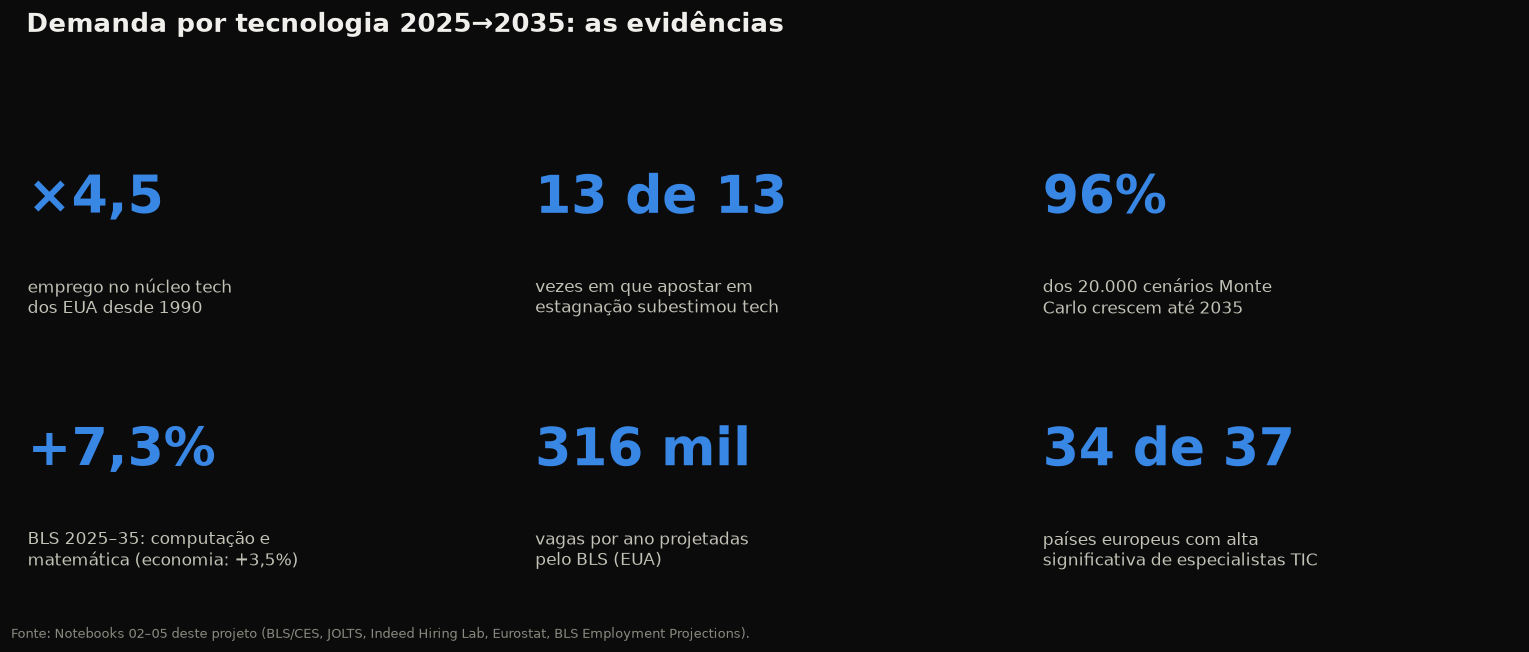

In [4]:
from techdemand import config
resumo = pd.read_csv(config.DATA_PROCESSED / "fred_panel.csv", index_col=0, parse_dates=True)
from techdemand import features as ft, models as m
tech = ft.annual(ft.tech_employment(resumo))
paths = m.block_bootstrap_paths(tech, h=10, n_sims=20_000, block=3, since=2001)
p_up = (paths.iloc[:, -1] > tech.iloc[-1]).mean() * 100

kpis = [
    ("×4,5", "emprego no núcleo tech\ndos EUA desde 1990"),
    ("13 de 13", "vezes em que apostar em\nestagnação subestimou tech"),
    (f"{p_up:.0f}%", "dos 20.000 cenários Monte\nCarlo crescem até 2035"),
    ("+7,3%", "BLS 2025–35: computação e\nmatemática (economia: +3,5%)"),
    ("316 mil", "vagas por ano projetadas\npelo BLS (EUA)"),
    ("34 de 37", "países europeus com alta\nsignificativa de especialistas TIC"),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 5.6))
for ax, (valor, texto) in zip(axes.flat, kpis):
    ax.axis("off")
    ax.text(0.03, 0.62, valor, fontsize=34, fontweight="bold", color=style.color_for("Núcleo tech"),
            transform=ax.transAxes, va="center")
    ax.text(0.03, 0.2, texto, fontsize=11, color=style.TEXT_SECONDARY, transform=ax.transAxes, va="center")
fig.suptitle("Demanda por tecnologia 2025→2035: as evidências", x=0.02, ha="left", fontsize=17,
             fontweight="bold", color=style.TEXT_PRIMARY)
style.source(fig, "Notebooks 02–05 deste projeto (BLS/CES, JOLTS, Indeed Hiring Lab, Eurostat, BLS Employment Projections).")
fig.tight_layout(rect=(0, 0, 1, 0.92))
style.save(fig, "05_03_painel_resumo")
plt.show()

## 4. Veredito

### A demanda por trabalho em tecnologia vai **aumentar** nos próximos 10 anos — mas de forma **mais seletiva** e mais lenta que na década de 2010.

**Evidências a favor do crescimento**

1. **Tendência estrutural de 35 anos:** o emprego no núcleo tech dos EUA multiplicou-se por ~4,5 e triplicou sua
   participação no emprego total. Todas as quedas anteriores, inclusive a da bolha .com (−17,6%), foram superadas.
2. **Backtest:** prever "sem crescimento" subestimou o emprego tech 10 anos depois em **todas** as 13 origens testadas.
3. **Modelos convergentes:** ensemble (+21%), Monte Carlo (mediana +35%, ~96% dos cenários positivos) e modelo
   estrutural (+28%) apontam alta até 2035.
4. **Projeção oficial independente:** o BLS projeta as ocupações de computação e matemática em **+7,3%**,
   ~2× a economia (+3,5%), com **~316 mil vagas por ano** e salário mediano de ~US$ 109 mil (2,1× a mediana geral).
5. **Fora dos EUA:** na Europa, 34 de 37 países mostram alta estatisticamente significativa de especialistas em TIC.

**Riscos e contrapontos (os dados também mostram)**

- **O ciclo atual é real:** o emprego tech recua desde dez/2022 (−5%), a 2ª maior queda desde 1990, e 2026 segue
  abaixo das previsões. Os anúncios de vaga de software estão ~20% abaixo do pré-pandemia, embora em alta desde 2025.
- **A composição muda:** cientistas de dados (+34,6%), segurança da informação (+21%) e pesquisa em computação
  (+21,8%) crescem forte; **programadores (−7,3%)**, suporte ao usuário (−3,5%) e administração de sistemas (−4,1%)
  encolhem. A automação (incluindo IA) desloca tarefas rotineiras.
- **Incerteza larga:** os modelos variam de estagnação (ETS amortecido) a +46% (ARIMA). A projeção do BLS por ocupação
  é bem mais conservadora que a extrapolação do setor.

### Implicação prática

Os dados **incentivam** a carreira em tecnologia, desde que direcionada às áreas com demanda crescente: **dados e IA,
segurança, arquitetura e pesquisa**. Funções baseadas em tarefas repetitivas de código ou suporte enfrentam mercado
mais difícil. A decisão de carreira deve olhar a **tendência de 10 anos**, não a manchete do trimestre.

### Limitações

- Emprego setorial (CES) ≠ ocupações (BLS EP): empresas tech empregam não técnicos, e técnicos trabalham fora delas.
- Os modelos extrapolam padrões históricos; choques sem precedente (ex.: adoção acelerada de IA) não estão no histórico.
- Dados do Brasil não foram incluídos por falta de série pública comparável por ocupação tech com histórico longo.
- O snapshot do BLS foi transcrito do site (o download automatizado é bloqueado) e validado por testes de consistência.